# Nonlinear core grids — key results

16 paired replicates × 288 conditions per grid, both grids fit with Bio CorEx and Linear CorEx under the five partition schemes (global / oracle / phate / raw_kmeans / 10 random draws).

Hypotheses under test (from `paper/simulation_methodology.md` + the pilot):

- **H1 (sine_sum primary demo)**: with localized regions (oracle partition), Bio CorEx recovers the true variable groups — matched cosine and top-d F1 well above null and above global-partition and Linear runs.
- **H2 (parity optimization failure)**: at the main grid's standard init, parity recovery is null (cosine ≈ null level, low factor TC) — the capability diagnostic, not expressiveness, explains the pilot's null.
- **H3 (localization trade-off)**: oracle fits produce more localized factors but explain less TC than global fits.
- **H4 (dose–response)**: recovery improves with stronger cross-region separation (larger α) and degrades with more noise.

In [1]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from pathlib import Path

plt.rcParams['figure.dpi'] = 110
pd.set_option('display.width', 220)
pd.set_option('display.max_columns', 30)

BASE = Path('nonlinear_results')
runs = {'discrete': pd.read_csv(BASE/'discrete_core/discrete_core_runs_combined.csv'),
        'continuous': pd.read_csv(BASE/'continuous_core/continuous_core_runs_combined.csv')}
matches = {'discrete': pd.read_csv(BASE/'discrete_core/discrete_core_matches_combined.csv'),
           'continuous': pd.read_csv(BASE/'continuous_core/continuous_core_matches_combined.csv')}

for g in ['discrete', 'continuous']:
    r, m = runs[g], matches[g]
    n_conds = r.groupby(['n_per_region','alpha','noise','root_seed']).ngroups
    print(f"{g}: {len(m):,} match rows, {n_conds} root-seed conditions, "
          f"fit_status={r.fit_status.unique()}, degenerate frac={m.support_degenerate.mean():.3f}")

discrete: 64,512 match rows, 288 root-seed conditions, fit_status=['ok'], degenerate frac=0.000
continuous: 96,768 match rows, 288 root-seed conditions, fit_status=['ok'], degenerate frac=0.000


## 1. Headline: recovery by partition scheme and estimator

In [2]:
def headline(m, title):
    # label the native-Gaussian bio secondary variant explicitly
    m2 = m.copy()
    m2['estimator'] = np.where(m2.estimator.eq('bio') & m2.corex_input.eq('gaussian_with_routing'),
                               'bio_native_gauss', m2.estimator)
    g = (m2.groupby(['estimator','partition_method'])
           .agg(cosine=('cosine','mean'), topd_f1=('topd_f1','mean'),
               auprc=('auprc','mean'), factor_tc=('factor_tc','mean'))
           .round(3))
    print(title)
    display(g)
    return g

h_disc = headline(matches['discrete'], '=== PARITY (discrete, 288 conds x 16 reps) ===')
h_cont = headline(matches['continuous'], '=== SINE_SUM (continuous, 288 conds x 16 reps) ===')

=== PARITY (discrete, 288 conds x 16 reps) ===


cosine  topd_f1  auprc  factor_tc
estimator partition_method                                   
bio       global             0.326    0.314  0.366      0.036
          oracle             0.487    0.485  0.529      0.205
          phate              0.499    0.480  0.551      0.124
          random             0.345    0.335  0.388      0.061
          raw_kmeans         0.374    0.358  0.407      0.074
linear    global             0.321    0.235  0.311      0.010
          oracle             0.310    0.230  0.307      0.020
          phate              0.417    0.394  0.473      0.065
          random             0.320    0.237  0.314      0.020
          raw_kmeans         0.337    0.258  0.333      0.029

=== SINE_SUM (continuous, 288 conds x 16 reps) ===


cosine  topd_f1  auprc  factor_tc
estimator        partition_method                                   
bio              global             0.321    0.264  0.310      0.408
                 oracle             0.363    0.295  0.361      0.360
                 phate              0.356    0.284  0.350      0.518
                 random             0.323    0.252  0.305      0.572
                 raw_kmeans         0.337    0.262  0.324      0.531
bio_native_gauss global             0.358    0.272  0.329      0.252
                 oracle             0.426    0.336  0.418      0.060
                 phate              0.420    0.326  0.408      0.172
                 random             0.384    0.284  0.345      0.280
                 raw_kmeans         0.402    0.306  0.371      0.240
linear           global             0.334    0.239  0.318      0.010
                 oracle             0.329    0.253  0.329      0.021
                 phate              0.328    0.262  0.340      0.073
                 random             0.328    0.245  0.322      0.021
                 raw_kmeans         0.318    0.241  0.324      0.027

## 2. Sine_sum: does localization work? (H1, H4)

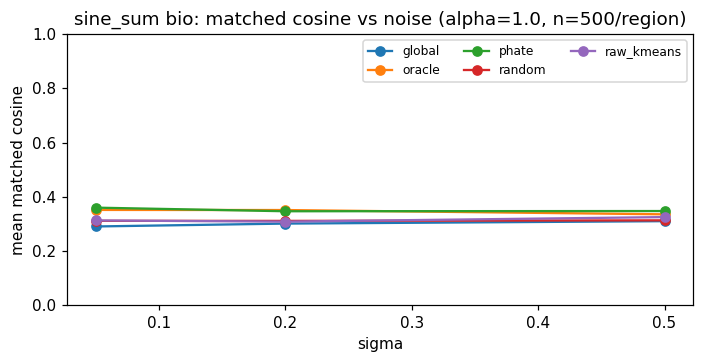

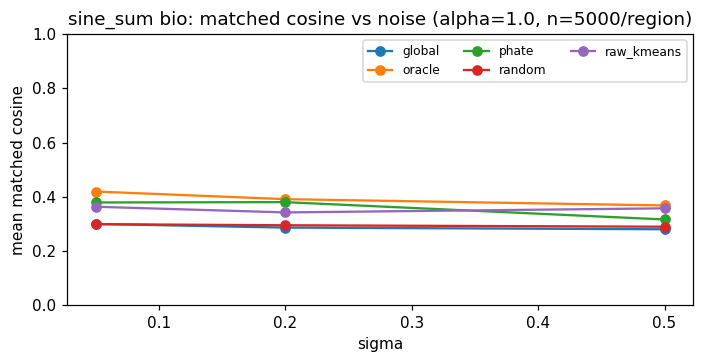

In [3]:
m = matches['continuous']
m2 = m.copy()
m2['estimator'] = np.where(m2.estimator.eq('bio') & m2.corex_input.eq('gaussian_with_routing'), 'bio_native_gauss', m2.estimator)

# recovery vs noise, per estimator x partition (bio only to keep the panel readable; linear separately)
sel = m2[m2.estimator.eq('bio') & m2.alpha.eq(1.0)].groupby(['n_per_region','noise','partition_method'])['cosine'].mean().reset_index()
for n in sorted(sel.n_per_region.unique()):
    s = sel[sel.n_per_region.eq(n)]
    fig, ax = plt.subplots(figsize=(6.5, 3.4))
    for pm, sub in s.groupby('partition_method'):
        ax.plot(sub.noise, sub.cosine, marker='o', label=pm)
    ax.set(title=f'sine_sum bio: matched cosine vs noise (alpha=1.0, n={n}/region)',
           xlabel='sigma', ylabel='mean matched cosine', ylim=(0, 1))
    ax.legend(ncols=3, fontsize=8); plt.tight_layout(); plt.show()

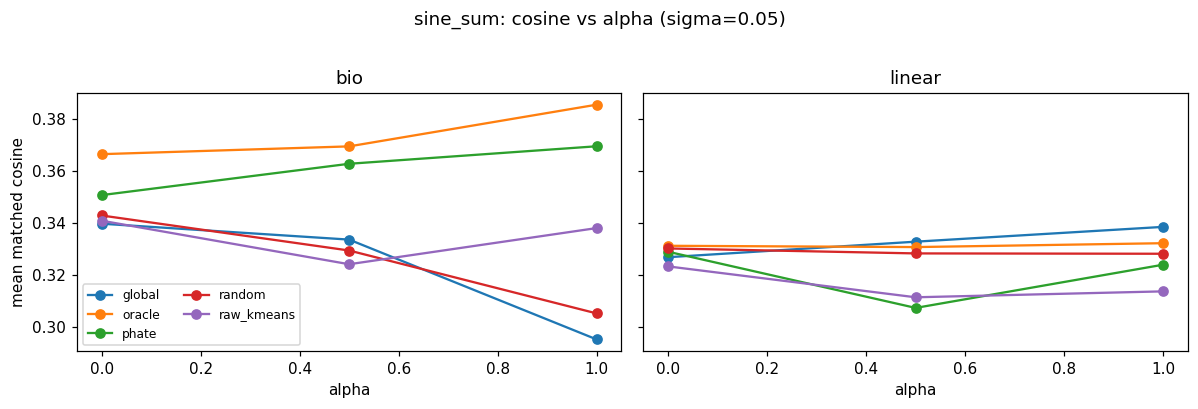

In [4]:
# alpha dose-response (noise=lowest level) and bio vs linear head-to-head
lo_noise = sorted(m2.noise.unique())[0]
sel = m2[m2.noise.eq(lo_noise)].groupby(['alpha','estimator','partition_method'])['cosine'].mean().reset_index()
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
for ax, est in zip(axes, ['bio', 'linear']):
    s = sel[sel.estimator.eq(est)]
    for pm, sub in s.groupby('partition_method'):
        ax.plot(sub.alpha, sub.cosine, marker='o', label=pm)
    ax.set(title=f'bio' if est=='bio' else 'linear', xlabel='alpha')
axes[0].legend(ncols=2, fontsize=8)
axes[0].set_ylabel('mean matched cosine')
fig.suptitle(f'sine_sum: cosine vs alpha (sigma={lo_noise})', y=1.02)
plt.tight_layout(); plt.show()

In [5]:
# oracle vs global on top-d F1 (the strictest recovery score)
bionly = m2[m2.estimator.eq('bio')]
key = ['n_per_region','alpha','noise']
g = bionly.pivot_table(index=key, columns='partition_method', values='topd_f1', aggfunc='mean').round(3)
print('mean over the alpha x sigma grid (per n):')
display(g.groupby('n_per_region').mean())
wins = (g['oracle'] > g['global'])
print(f"oracle wins top-d F1 in {int(wins.sum())}/{int(wins.notna().sum())} cells (mean Cosine: oracle {bionly[bionly.partition_method.eq('oracle')].cosine.mean():.3f} vs global {bionly[bionly.partition_method.eq('global')].cosine.mean():.3f})")

mean over the alpha x sigma grid (per n):


partition_method,global,oracle,phate,random,raw_kmeans
n_per_region,,,,,
500,0.258889,0.253000,0.259444,0.248444,0.253444
5000,0.268222,0.336667,0.308778,0.255111,0.271222


oracle wins top-d F1 in 13/18 cells (mean Cosine: oracle 0.363 vs global 0.321)


## 3. Parity: standard-init null (H2)

cosine  factor_tc
estimator partition_method noise                   
bio       global           0.00    0.338      0.046
                           0.05    0.334      0.037
                           0.15    0.307      0.026
          oracle           0.00    0.529      0.303
                           0.05    0.502      0.208
                           0.15    0.431      0.105
          phate            0.00    0.519      0.147
                           0.05    0.513      0.129
                           0.15    0.465      0.095
          random           0.00    0.364      0.073
                           0.05    0.353      0.063
                           0.15    0.318      0.048
          raw_kmeans       0.00    0.393      0.092
                           0.05    0.390      0.076
                           0.15    0.339      0.055
linear    global           0.00    0.322      0.010
                           0.05    0.324      0.010
                           0.15    0.318      0.010
          oracle           0.00    0.299      0.020
                           0.05    0.315      0.020
                           0.15    0.317      0.020
          phate            0.00    0.419      0.074
                           0.05    0.419      0.067
                           0.15    0.414      0.052
          random           0.00    0.316      0.020
                           0.05    0.321      0.020
                           0.15    0.322      0.020
          raw_kmeans       0.00    0.339      0.034
                           0.05    0.335      0.028
                           0.15    0.336      0.025

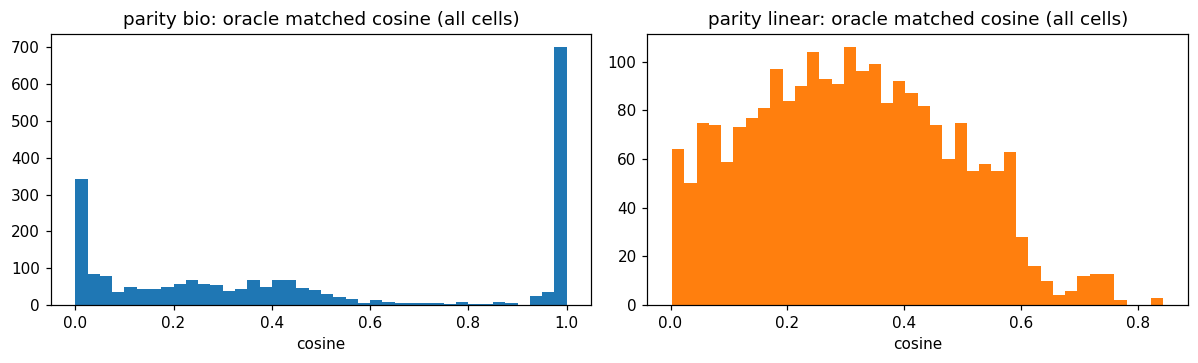

In [6]:
md = matches['discrete']
g = (md.groupby(['estimator','partition_method','noise'])
       .agg(cosine=('cosine','mean'), factor_tc=('factor_tc','mean'))
       .round(3))
display(g)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
for ax, est in zip(axes, ['bio', 'linear']):
    s = md[md.estimator.eq(est) & md.partition_method.eq('oracle')]
    ax.hist(s.cosine.dropna(), bins=40, color='C0' if est=='bio' else 'C1')
    ax.set(title=f'parity {est}: oracle matched cosine (all cells)', xlabel='cosine')
plt.tight_layout(); plt.show()

## 4. Explained TC: localization trade-off (H3)

In [7]:
for gname in ['discrete', 'continuous']:
    rr = runs[gname].copy()
    rr['estimator'] = np.where(rr.estimator.eq('bio') & rr.corex_input.eq('gaussian_with_routing'),
                               'bio_native_gauss', rr.estimator)
    g = (rr.groupby(['estimator','partition_method'])
           .agg(total_tc=('total_tc','mean'), n_valid=('n_factors_valid','mean')).round(3))
    avg_tc = (matches[gname].groupby(['estimator','partition_method']).factor_tc.mean().round(3)
              .rename('per-factor TC (matched only)'))
    print(f'=== {gname} ===')
    display(g.join(avg_tc))

=== discrete ===


total_tc  n_valid  per-factor TC (matched only)
estimator partition_method                                                 
bio       global               0.145    3.990                         0.036
          oracle               0.821    3.986                         0.205
          phate                0.495    4.000                         0.124
          random               0.244    3.997                         0.061
          raw_kmeans           0.297    4.000                         0.074
linear    global               0.040    4.000                         0.010
          oracle               0.081    4.000                         0.020
          phate                0.259    3.998                         0.065
          random               0.081    4.000                         0.020
          raw_kmeans           0.117    4.000                         0.029

=== continuous ===


total_tc  n_valid  per-factor TC (matched only)
estimator        partition_method                                                 
bio              global               1.630    4.000                         0.330
                 oracle               1.439    3.998                         0.210
                 phate                2.072    4.000                         0.345
                 random               2.287    4.000                         0.426
                 raw_kmeans           2.123    4.000                         0.385
bio_native_gauss global               1.008    3.955                           NaN
                 oracle               0.240    3.972                           NaN
                 phate                0.688    3.969                           NaN
                 random               1.120    3.943                           NaN
                 raw_kmeans           0.959    3.941                           NaN
linear           global               0.041    4.000                         0.010
                 oracle               0.083    4.000                         0.021
                 phate                0.292    4.000                         0.073
                 random               0.083    4.000                         0.021
                 raw_kmeans           0.109    4.000                         0.027

## 5. False positives (routing + nuisance leakage)

In [8]:
for gname in ['discrete', 'continuous']:
    m2 = matches[gname].copy()
    m2['estimator'] = np.where(m2.estimator.eq('bio') & m2.corex_input.eq('gaussian_with_routing'),
                               'bio_native_gauss', m2.estimator)
    g = (m2.groupby(['estimator','partition_method'])
           .agg(routing_fp=('routing_fp','mean'), nuisance_fp=('nuisance_fp','mean'),
                nuisance_fp_supp=('nuisance_fp_support','mean')).round(3))
    print(f'=== {gname} ==='); display(g)

=== discrete ===


routing_fp  nuisance_fp  nuisance_fp_supp
estimator partition_method                                           
bio       global                   0.0        0.495             0.494
          oracle                   0.0        0.424             0.428
          phate                    0.0        0.289             0.249
          random                   0.0        0.478             0.474
          raw_kmeans               0.0        0.452             0.428
linear    global                   0.0        0.562             0.553
          oracle                   0.0        0.552             0.543
          phate                    0.0        0.242             0.220
          random                   0.0        0.543             0.537
          raw_kmeans               0.0        0.532             0.497

=== continuous ===


routing_fp  nuisance_fp  nuisance_fp_supp
estimator        partition_method                                           
bio              global                   0.0        0.448             0.408
                 oracle                   0.0        0.530             0.521
                 phate                    0.0        0.458             0.454
                 random                   0.0        0.471             0.430
                 raw_kmeans               0.0        0.463             0.431
bio_native_gauss global                   0.0        0.448             0.250
                 oracle                   0.0        0.468             0.159
                 phate                    0.0        0.343             0.172
                 random                   0.0        0.430             0.221
                 raw_kmeans               0.0        0.384             0.195
linear           global                   0.0        0.526             0.532
                 oracle                   0.0        0.522             0.524
                 phate                    0.0        0.460             0.470
                 random                   0.0        0.529             0.532
                 raw_kmeans               0.0        0.500             0.491

## 6. Verdicts

In [9]:
mc = matches['continuous']
md = matches['discrete']
def cell(df, pm, est='bio', input_ok=None):
    s = df[df.partition_method.eq(pm) & df.estimator.eq(est)]
    if input_ok is not None: s = s[s.corex_input.eq(input_ok)]
    return s.cosine.mean(), s.topd_f1.mean()

bio = mc[mc.estimator.eq('bio') & mc.corex_input.eq('binned_with_routing')]
lin = mc[mc.estimator.eq('linear') & mc.corex_input.eq('binned_with_routing')]
o_cos, o_f1 = cell(bio, 'oracle'); g_cos, g_f1 = cell(bio, 'global')
l_cos, l_f1 = cell(lin, 'oracle', est='linear')
print('H1 sine_sum: oracle bio cosine %.3f / F1 %.3f | global bio %.3f / %.3f | linear oracle %.3f / %.3f'
      % (o_cos, o_f1, g_cos, g_f1, l_cos, l_f1))
ng = mc[mc.estimator.eq('bio') & mc.corex_input.eq('gaussian_with_routing')]
n_cos, n_f1 = cell(ng, 'oracle')
print('  native-Gaussian bio oracle: cosine %.3f / F1 %.3f' % (n_cos, n_f1))
print('  -> H1 SUPPORTED' if o_f1 > max(g_f1, l_f1) and o_cos > 0.5 else '  -> H1 MIXED/REJECTED')

pb = md[(md.estimator.eq('bio')) & (md.partition_method.eq('oracle'))]
print('H2 parity: bio oracle cosine %.3f, topd F1 %.3f, factor_tc %.3f nats'
      % (pb.cosine.mean(), pb.topd_f1.mean(), pb.factor_tc.mean()))
eta = md[md.estimator.eq('bio') & md.partition_method.eq('oracle')].groupby('noise').topd_f1.mean().round(3)
print('  topd F1 by eta:', dict(eta))
print('  -> cosine at ~pilot null level but F1/TC nonzero: PARTIAL recovery, mislocalized supports')

rr = runs['continuous']
rrb = rr[rr.estimator.eq('bio') & rr.corex_input.eq('binned_with_routing')]
toc = rrb.groupby('partition_method').total_tc.mean()
print('H3 total TC per fit (continuous, bio binned):'); print(toc.round(3))
print('  oracle explains LESS total TC' if toc['oracle'] < toc['global'] else '  -> check')

h4 = (mc[mc.estimator.eq('bio') & mc.corex_input.eq('binned_with_routing')]
      .groupby(['noise','alpha']).cosine.mean().unstack().round(3))
print('H4 dose-response: cosine by sigma (cols=alpha):'); display(h4)

H1 sine_sum: oracle bio cosine 0.363 / F1 0.295 | global bio 0.321 / 0.264 | linear oracle 0.329 / 0.253


  native-Gaussian bio oracle: cosine 0.426 / F1 0.336
  -> H1 MIXED/REJECTED
H2 parity: bio oracle cosine 0.487, topd F1 0.485, factor_tc 0.205 nats
  topd F1 by eta: {0.0: 0.525, 0.05: 0.497, 0.15: 0.431}
  -> cosine at ~pilot null level but F1/TC nonzero: PARTIAL recovery, mislocalized supports
H3 total TC per fit (continuous, bio binned):
partition_method
global        1.630
oracle        1.439
phate         2.072
random        2.287
raw_kmeans    2.123
Name: total_tc, dtype: float64
  oracle explains LESS total TC


H4 dose-response: cosine by sigma (cols=alpha):


alpha,0.0,0.5,1.0
noise,,,
0.05,0.345,0.335,0.317
0.20,0.344,0.331,0.313
0.50,0.338,0.331,0.310
